# Lab 1 — Limit order book data with LOBSTER

**COMP0049 Market Microstructure · MSc Computational Finance, UCL · 2026–27**

**Learning outcomes.** By the end of the session you should be able to

1. set up Python and use the main `pandas` functions needed for high-frequency data;
2. load and analyse limit order book (LOB) data in the LOBSTER format;
3. build indicators of **liquidity** (e.g. depth) and of **risk / cost of trading** (e.g. spread) from LOB data;
4. compare the empirical properties of different classes of stocks (**small-tick** vs **large-tick**).

**Theory.** Lecture notes Ch. 1–3 (LOB definitions, the tick size, empirical properties) and §8.1 (the LOBSTER dataset and the Lab 1 exercises).

| Part | What we do | Lecture notes | 
|---|---|---|
| 0 | Setting up Python, finding the data| — |
| 1 | The **message file**: events, event types, halts, executions vs trades, hidden liquidity | §2.4 |
| 2 | The **order book file**: best quotes, spread, mid-price, gaps, a snapshot of the book | §2.1, §3.1.2 | 
| 3 | Event time vs clock time | - | 5 |
| 4 | Liquidity and risk indicators for a **small-tick** and a **large-tick** stock | §2.5, §3.1 | 
| 5 | Different classes of stocks on 6 October 2025 | Fig. 3.10 | 
| 6 | Selective liquidity taking: the consumption ratio | §3.1.5 |

## Data access and rules

**1. LOBSTER (NASDAQ academic data).** The course has a shared student account:

- https://php.lobsterdata.com/index.php
- Account: `studentlobsterucl@gmail.com`
- Password: `Ucl_lobster`

Please use it responsibly, as the account is shared with the whole class and can be suspended for all of us:

- **No bulk downloads.** Request only the stock days you need for the labs or for your project, one request at a time.
- **Read the terms of use and the data request rules** on the LOBSTER site before submitting a request.
- **No redistribution.** The data are for academic use within this module only: do not share, publish or resell them.
- **If the site stops responding** or a download hangs, clear your browser cache and cookies (or use a private window) and log in again.

**2. Other data for summer projects (FX, trades & quotes).** Dukascopy offers free historical data (tick-level FX quotes, among others):

- https://www.dukascopy.com/swiss/english/marketwatch/historical/

Download the files **manually** from the website: do not scrape the site or automate the downloads. You can build the dataset for your project by hand, one instrument and period at a time.

> **Be compliant.** Every data provider has terms of use. Breaking them (bulk or automated downloads, redistribution) can get the course account suspended and is a disciplinary matter. If in doubt, ask before downloading.

LOBSTER (https://lobsterdata.com) reconstructs the NASDAQ limit order book from the exchange's official TotalView-ITCH feed. For each stock and day we get **two files with the same number of rows**:

- `TICKER_DATE_34200000_57600000_message_10.csv` — one row per **event** (a submission, cancellation, deletion or execution);
- `TICKER_DATE_34200000_57600000_orderbook_10.csv` — the **state of the book** (10 best price levels on each side) immediately *after* that event.

`34200000` and `57600000` are the start and end of the sample in milliseconds after midnight, i.e. 09:30 and 16:00 New York time; `10` is the number of price levels.

| Stocks | Trading day | Used in |
|---|---|---|
| AMZN, MSFT | 21 June 2012 (LOBSTER's free sample) | Parts 1–4|
| TSLA, GOOG, BAC, BKNG | 6 October 2025 | Parts 5–6 |

**Where to put the files.** Download the 10-level files from the module SharePoint (link on Moodle) and save them in a folder called `data` next to this notebook. The AMZN and MSFT samples can also be downloaded for free from https://lobsterdata.com/info/DataSamples.php.

**Reference.** Bouchaud, Bonart, Donier & Gould, *Trades, Quotes and Prices*, CUP 2018 (free through the UCL library on Cambridge Core).

---
# Part 0 — Setting up Python

## 0.1 Libraries

We only need the standard scientific stack: `numpy` (arrays), `pandas` (tables and time series) and `matplotlib` (plots). If an import fails, install the package from a terminal with `pip install numpy pandas matplotlib` and restart the kernel.

In [2]:
import gc
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, MaxNLocator, NullFormatter

print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {mpl.__version__}")

pandas 3.0.5 | numpy 2.5.2 | matplotlib 3.11.1


In [3]:
# Constants used throughout the lab 
START_TRAD  = 9.5 * 60 * 60     # 09:30:00 in seconds after midnight (market open)
END_TRAD    = 16.0 * 60 * 60    # 16:00:00 in seconds after midnight (market close)
PRICE_SCALE = 10_000            # LOBSTER stores prices as dollars x 10,000  ($51.40 -> 514000)
TICK        = 100               # tick size tau = $0.01 = 100 LOBSTER price units (US stocks above $1)
EMPTY_LEVEL = 9_999_999_999     # LOBSTER's filler price for an unoccupied level (negative on the bid side)

# Plot style: one colour per meaning, used consistently 
BID_COLOR, ASK_COLOR = "#2a78d6", "#eb6834"            # bid side = blue, ask side = orange
VISIBLE_COLOR, HIDDEN_COLOR = "#52514e", "#eda100"     # visible executions = grey, hidden = amber
STOCK_PALETTE = ["#6250d6", "#1baf7a"]                  
ACCENT, MUTED, LIGHT = "#2a78d6", "#898781", "#c3c2b7"

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 100, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": LIGHT, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})


def fmt(table, decimals=2):
    """Format the numbers of a summary table for display: thousands separators and a fixed number of decimals."""
    def one(v):
        if isinstance(v, (bool, np.bool_, str)):
            return v
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        if isinstance(v, (float, np.floating)):
            return f"{v:,.{decimals}f}"
        return v
    return table.apply(lambda column: column.map(one))


def hours(index):
    """Time of day in hours (9.5 = 09:30) for a DatetimeIndex, so different trading days share one axis."""
    return (index - index.normalize()) / pd.Timedelta(hours=1)


def time_axis(ax):
    """Format an x-axis expressed in hours-of-day as 09:30 ... 16:00."""
    ax.set_xlim(9.5, 16)
    ax.set_xticks(range(10, 17))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda h, _: f"{int(h):02d}:{int(round((h % 1) * 60)):02d}"))
    ax.set_xlabel("Time of day (New York)")

## 0.2 Where is the data?

The next cell looks for the LOBSTER files in a few standard places and stops at the first folder that contains them:

1. a folder you set by hand in `MY_DATA_DIR`;
2. `data/` next to this notebook;
3. `Microstructure demos/LOBdemo25/data/` next to this notebook.

It then builds a small catalogue of what it found, reading the ticker, the date and the number of levels from each file name.

In [4]:
MY_DATA_DIR = None      # e.g. Path("/full/path/to/the/folder/with/the/csv/files") if the search below fails

here = Path.cwd()
candidates = [
    MY_DATA_DIR,
    here / "data",
    here / "LOBdemo25" / "data",
    here / "Microstructure demos" / "LOBdemo25" / "data",
    here.parent / "LOBdemo25" / "data",
    Path.home() / "Desktop" / "TA Microstructure" / "Microstructure demos" / "LOBdemo25" / "data",
]
DATA_DIR = next((Path(p) for p in candidates
                 if p is not None and Path(p).is_dir() and any(Path(p).glob("*_message_*.csv"))), None)
if DATA_DIR is None:
    raise FileNotFoundError("No LOBSTER files found. Put the csv files in a folder called 'data' next to this "
                            "notebook, or set MY_DATA_DIR above to the folder that contains them.")

# Catalogue of the LOBSTER files: (ticker, date, levels) -> {'message': path, 'orderbook': path} 

# A regular expression that describes a LOBSTER file name, e.g. "AMZN_2012-06-21_34200000_57600000_message_10.csv".
# Each (?P<name>...) group captures one piece of the name so that we can read it back by name afterwards:
#   ticker  -> letters (and a dot, for tickers like BRK.B)
#   date    -> yyyy-mm-dd
#   \d+_\d+ -> start and end time in milliseconds after midnight (not captured: we don't need them)
#   kind    -> "message" or "orderbook"
#   levels  -> number of price levels in the file (10, 50, ...)
FILE_PATTERN = re.compile(r"^(?P<ticker>[A-Za-z.]+)_(?P<date>\d{4}-\d{2}-\d{2})_\d+_\d+_"
                          r"(?P<kind>message|orderbook)_(?P<levels>\d+)\.csv$")

catalogue = {}
for path in sorted(DATA_DIR.glob("*.csv")):        # every csv file in the data folder
    match = FILE_PATTERN.match(path.name)
    if match:                                       # skip files whose name does not follow the LOBSTER convention
        key = (match["ticker"], match["date"], int(match["levels"]))
        # setdefault: create the entry {} for this (ticker, date, levels) if it does not exist yet, then
        # store the path under "message" or "orderbook" -> the two files of a stock-day end up in the same entry
        catalogue.setdefault(key, {})[match["kind"]] = path

# Print the data folder as a path relative to the notebook if possible (shorter), otherwise the full path
try:
    shown = DATA_DIR.relative_to(here)
except ValueError:                                  # raised when DATA_DIR is not inside the notebook folder
    shown = DATA_DIR
print(f"Data folder: {shown}")

# Summary table: one row per stock day, with the size of the two files in MB (None if a file is missing)
pd.DataFrame([{"ticker": t, "date": d, "levels": n,
               "message file (MB)": round(f["message"].stat().st_size / 1e6, 1) if "message" in f else None,
               "orderbook file (MB)": round(f["orderbook"].stat().st_size / 1e6, 1) if "orderbook" in f else None}
              for (t, d, n), f in catalogue.items()]).sort_values(["date", "ticker"]).reset_index(drop=True)

Data folder: Microstructure demos/LOBdemo25/data


,ticker,date,levels,message file (MB),orderbook file (MB)
0,AMZN,2012-06-21,10,11.2,63.2
1,MSFT,2012-06-21,10,27.6,170.2
2,BAC,2025-10-06,10,19.9,97.0
3,BKNG,2025-10-06,10,2.4,11.8
4,GOOG,2025-10-06,10,113.3,563.7
5,TSLA,2025-10-06,10,95.2,465.7


In [5]:
def lobster_files(ticker, date=None, levels=None):
    """Return the message and orderbook paths for a ticker (the most recent day if several are available)."""
    # 1. Keep the catalogue entries that match the request. Each key is a tuple (ticker, date, levels),
    #    so k[0] is the ticker, k[1] the date and k[2] the number of levels.
    #    "date is None or ..." means: if no date was asked for, accept any date (same for levels).
    keys = [k for k in catalogue
            if k[0] == ticker and (date is None or k[1] == date) and (levels is None or k[2] == levels)]
    if not keys:                                    # the list is empty: nothing matched
        raise FileNotFoundError(f"No LOBSTER files for {ticker} (date={date}, levels={levels}) in {DATA_DIR}")

    # 2. If several stock days match (e.g. TSLA 2019 and TSLA 2025), take the most recent one:
    #    sort by (date, levels) and keep the last element. Dates as "yyyy-mm-dd" sort correctly as strings.
    key = sorted(keys, key=lambda k: (k[1], k[2]))[-1]

    # 3. Both files must be present. {"message", "orderbook"} <= set(files) reads "is a subset of":
    #    True only if the entry has a path for the message AND for the orderbook file.
    files = catalogue[key]
    if not {"message", "orderbook"} <= set(files):
        raise FileNotFoundError(f"{ticker} {key[1]}: need both the message and the orderbook file")

    # 4. Return everything in one dictionary. **files unpacks {"message": path, "orderbook": path}
    #    into the new dictionary, so the result has the keys ticker, date, levels, message, orderbook.
    return {"ticker": key[0], "date": key[1], "levels": key[2], **files}

## 0.3 `pandas` warm-up

Everything in this lab is done with a handful of `pandas` operations. 

In [6]:
toy = pd.DataFrame({
    "Time":  [34200.10, 34200.35, 34200.35, 34201.20, 34202.75, 34203.05],   # seconds after midnight
    "Type":  [1, 1, 4, 3, 1, 4],
    "Size":  [100, 50, 50, 100, 200, 120],
    "Price": [1000100, 1000300, 1000300, 1000100, 1000200, 1000200],
})

toy["PriceUSD"] = toy["Price"] / PRICE_SCALE          # 1. a new column computed from an existing one
executions = toy[toy["Type"] == 4]                     # 2. a boolean mask keeps the rows where the condition holds
toy["PrevPrice"] = toy["Price"].shift(1)               # 3. shift(1) = the value on the previous row ("just before")
per_type = toy.groupby("Type")["Size"].agg(["count", "sum"])   # 4. split by a key, then aggregate each group

print("Executions only:");  display(executions)
print("Count and volume per event type:");  display(per_type)

Executions only:


,Time,Type,Size,Price,PriceUSD
2,34200.35,4,50,1000300,100.03
5,34203.05,4,120,1000200,100.02


Count and volume per event type:


,count,sum
Type,,
1,3,350
3,1,100
4,2,170


In [7]:
# 5. A time index unlocks time based operations: slicing by time of day and resampling into regular bins
toy.index = pd.Timestamp("2025-10-06") + pd.to_timedelta(toy["Time"], unit="s")
print(toy.index[0])                                   # 34200.10 s after midnight = 09:30:00.100
toy.resample("1s")["Size"].sum()                      # total size in each one-second bin

2025-10-06 09:30:00.100000


Time
2025-10-06 09:30:00    200
2025-10-06 09:30:01    100
2025-10-06 09:30:02    200
2025-10-06 09:30:03    120
Freq: s, Name: Size, dtype: int64

---
# Part 1 — The message file

## 1.1 What is in it?

Each row is one **event** that changed the visible book. There are six columns:

| Column | Meaning |
|---|---|
| `Time` | seconds after midnight, with a precision of up to nanoseconds |
| `Type` | type of event (table below) |
| `OrderID` | unique identifier of the limit order involved (no information about the trader) |
| `Size` | number of shares |
| `Price` | dollar price × 10,000 |
| `TradeDirection` | side of the **limit order** involved: `+1` buy (bid side), `-1` sell (ask side) |

| `Type` | Event |
|---|---|
| 1 | submission of a new limit order |
| 2 | cancellation (partial deletion of a limit order) |
| 3 | deletion (total deletion of a limit order) |
| 4 | execution of a **visible** limit order |
| 5 | execution of a **hidden** limit order |
| 6 | cross trade (e.g. the opening auction) |
| 7 | trading halt indicator |

> **Sign convention.** `TradeDirection` is the side of the *resting limit order*. An execution with `TradeDirection = -1` means that a **sell** limit order was hit, i.e. the trade was initiated by a **buyer**. The sign of the market order used in the theory chapters is therefore $\epsilon = -\texttt{TradeDirection}$. 

## 1.2 Loading the data

`load_messages` reads the file, keeps the events between 09:30 and 16:00, and indexes the rows by their timestamp. Files downloaded recently have a seventh, empty column, so we read the first six only. We also keep `row_index`, the position of each row in the raw file: it is what ties the message file to the order book file.

In [8]:
MESSAGE_COLUMNS = ["Time", "Type", "OrderID", "Size", "Price", "TradeDirection"]


def load_messages(ticker, date=None, levels=None, start=START_TRAD, end=END_TRAD):
    """Load a LOBSTER message file, keeping the events between `start` and `end` (seconds after midnight)."""
    files = lobster_files(ticker, date, levels)
    msg = pd.read_csv(files["message"], header=None, names=MESSAGE_COLUMNS, usecols=range(6))

    msg["row_index"] = np.arange(len(msg))            # row number in the raw file -> aligns the order book file
    msg = msg[(msg["Time"] >= start) & (msg["Time"] <= end)].copy()

    # timestamp = trading day + seconds after midnight
    msg.index = pd.Timestamp(files["date"]) + pd.to_timedelta(msg["Time"].to_numpy(), unit="s")
    msg.index.name = "DateTime"
    return msg


STOCKS = ["AMZN", "MSFT"]                              
TICKER_COLORS = dict(zip(STOCKS, STOCK_PALETTE))       # one colour per stock, used in every figure
msg_book = {ticker: load_messages(ticker) for ticker in STOCKS}

> **Question 1.1.** Check that the function has done what we think it should: print the first and the last rows of the two tables.

In [9]:
msg_book["MSFT"].head()

,Time,Type,OrderID,Size,Price,TradeDirection,row_index
DateTime,,,,,,,
2012-06-21 09:30:00.013994120,34200.013994,3,16085616,100,310400,-1,0
2012-06-21 09:30:00.013994120,34200.013994,1,16116348,100,310500,-1,1
2012-06-21 09:30:00.015247805,34200.015248,1,16116658,100,310400,-1,2
2012-06-21 09:30:00.015442111,34200.015442,1,16116704,100,310500,-1,3
2012-06-21 09:30:00.015789148,34200.015789,1,16116752,100,310600,-1,4


In [10]:
msg_book["AMZN"].tail()

,Time,Type,OrderID,Size,Price,TradeDirection,row_index
DateTime,,,,,,,
2012-06-21 15:59:59.872741285,57599.872741,3,286560364,100,2207600,-1,269743
2012-06-21 15:59:59.903989046,57599.903989,3,287142900,100,2206200,-1,269744
2012-06-21 15:59:59.955241980,57599.955242,3,286967592,170,2206900,-1,269745
2012-06-21 15:59:59.958244616,57599.958245,1,287174077,100,2206300,-1,269746
2012-06-21 15:59:59.959359650,57599.959360,3,287174077,100,2206300,-1,269747


> **Question 1.2.** How many events were recorded on this trading day for the two stocks?
>
> **Question 1.3.** Up to which temporal precision are the events recorded (minutes, seconds, …)?

In [11]:
for ticker in STOCKS:
    m = msg_book[ticker]
    gaps = np.diff(m["Time"].to_numpy())
    print(f"{ticker}: {len(m):>9,} events | first {str(m.index[0])[11:]} | last {str(m.index[-1])[11:]} "
          f"| {len(m) / (END_TRAD - START_TRAD):5.1f} events per second on average "
          f"| {100 * np.mean(gaps == 0):4.1f}% of events share their timestamp with the previous one")

# The first 11 characters (positions 0 to 10) are the date plus the space, 2012-06-21 , so [11:] keeps everything from position 11 to the end: 09:30:00.017459617.

AMZN:   269,748 events | first 09:30:00.017459617 | last 15:59:59.959359650 |  11.5 events per second on average |  3.1% of events share their timestamp with the previous one
MSFT:   668,765 events | first 09:30:00.013994120 | last 15:59:59.907796528 |  28.6 events per second on average |  8.6% of events share their timestamp with the previous one


**Answers.** (1.2) AMZN has 269,748 events and MSFT 668,765: about 12 and 29 events per second on average over the 6.5 hour session.

(1.3) Times are given in seconds after midnight with nine decimals, i.e. to the **nanosecond** ($10^{-9}$ s): the last AMZN event is stamped 15:59:59.959359650. Several events can carry exactly the same timestamp (3% of the AMZN rows and 9% of the MSFT rows share theirs with the previous row). This is typically one market order executing against several limit orders.

## 1.3 What happens in a limit order book?

> **Question 1.4.** Write a `summary` function that groups the events by type and, for each type, (1) counts the events and (2) sums the number of shares, both in absolute terms and as a share of the total.
>
> **Question 1.5.** What do you observe about how often the different events occur?

In [12]:
EVENT_NAMES = {1: "new limit order", 2: "partial cancellation", 3: "total deletion",
               4: "execution (visible)", 5: "execution (hidden)", 6: "cross trade", 7: "trading halt"}


def summary(msg):
    """Number of events and number of shares per event type, in absolute terms and in % of the total."""
    out = msg.groupby("Type")["Size"].agg(events="count", shares="sum")
    out["events %"] = 100 * out["events"] / out["events"].sum()
    out["shares %"] = 100 * out["shares"] / out["shares"].sum()
    out.insert(0, "description", out.index.map(EVENT_NAMES))
    return out.round(2)

# The “total shares” is not a traded volume or a quantity ever present in the book. 
# It adds up the sizes of all events, so the same 100 shares count once when the order is submitted and again when it is deleted (or executed). 
# It is only a denominator for comparing the types with each other. The traded volume is the sum of Size over types 4 and 5 only,

for ticker in STOCKS:
    table = summary(msg_book[ticker])
    print(f"{ticker}: {table.loc[1, 'events'] / table.loc[[4, 5], 'events'].sum():.1f} new limit orders per execution | "
          f"{100 * table.loc[[2, 3], 'shares'].sum() / table.loc[1, 'shares']:.1f}% of the submitted volume is cancelled or deleted")
    display(table)

AMZN: 11.6 new limit orders per execution | 94.4% of the submitted volume is cancelled or deleted


,description,events,shares,events %,shares %
Type,,,,,
1,new limit order,131954,13027425,48.92,49.86
2,partial cancellation,2917,345515,1.08,1.32
3,total deletion,123458,11946930,45.77,45.72
4,execution (visible),8974,613248,3.33,2.35
5,execution (hidden),2445,197507,0.91,0.76


MSFT: 9.9 new limit orders per execution | 92.4% of the submitted volume is cancelled or deleted


,description,events,shares,events %,shares %
Type,,,,,
1,new limit order,329566,174783168,49.28,50.35
2,partial cancellation,5602,2179740,0.84,0.63
3,total deletion,300183,159320803,44.89,45.90
4,execution (visible),29798,9887669,4.46,2.85
5,execution (hidden),3616,936752,0.54,0.27


**Answers.**

- **Limit orders dominate.** About half of all events are submissions of new limit orders (49%) and almost as many are cancellations or deletions (46–47%). Only 4–5% of the events are executions.
- **Most limit orders are never executed.** In shares, 94% (AMZN) and 92% (MSFT) of the submitted volume is cancelled or deleted, and there are 10 to 12 new limit orders for every execution.
- **Orders are withdrawn whole.** Total deletions are forty to fifty times more frequent than partial cancellations: an order is removed (and typically re-submitted at another price) rather than reduced.
- **Hidden executions are a minority, but a larger one for AMZN** (0.9% of events against 0.5% for MSFT). 

## 1.4 Trading halts

When trading in a stock is halted, LOBSTER writes a message of type `7`. The state is encoded in the `Price` column, with `TradeDirection = -1` and all other fields set to 0:

| `Price` | Meaning |
|---|---|
| `-1` | trading **halted** |
| `0` | **quoting resumes**, trading still halted |
| `1` | **trading resumes** |

The matching rows of the order book file simply repeat the previous state of the book; the reason for the halt is not recorded. Halts are triggered by news pending, by the Limit Up–Limit Down bands, or by technical problems. NASDAQ publishes the halts and their reason codes at https://www.nasdaqtrader.com/trader.aspx?id=TradeHalts.

> **Question 1.6.** Was trading halted for AMZN or MSFT on this day?

In [13]:
def check_for_halts(msg, ticker=""):
    """Print the times of the trading halt messages (type 7), if any."""
    halts = msg[msg["Type"] == 7]
    states = {-1: "trading halted", 0: "quoting resumed", 1: "trading resumed"}
    if halts.empty:
        print(f"{ticker}: no trading halts detected.")
    for time, price in zip(halts.index, halts["Price"]):
        print(f"{ticker}: {states.get(price, 'unknown halt message')} at {time.time()}")
    return halts


for ticker in STOCKS:
    check_for_halts(msg_book[ticker], ticker)

AMZN: no trading halts detected.
MSFT: no trading halts detected.


## 1.5 Executions are not trades

LOBSTER records the **executions of limit orders**, not what one would intuitively call trades (market orders).

Suppose 1,000 shares are offered at the best ask and a market order to buy 1,000 shares arrives. What appears in the message file depends on how the queue is made up:

- **one** sell limit order of 1,000 shares → one execution of 1,000 shares: execution and trade coincide;
- **five** sell limit orders of 200 shares each → five executions of 200 shares, with the same timestamp and the same direction.

So the size of a market order has to be *inferred*, by grouping the executions that share a timestamp and a side. This is only an approximation — real data contain coincidences and errors — but it is the standard first step (lecture notes §2.4.2).

> **Question 1.7.** Reconstruct the market orders of the two stocks. How many executions does a market order trigger on average? What is the typical market order size?

In [14]:
def market_orders(msg, types=(4, 5)):
    """Group executions with the same timestamp and the same side into one (approximate) market order."""
    executions = msg[msg["Type"].isin(types)]
    mo = (executions.groupby(["Time", "TradeDirection"], sort=True)
                    .agg(size=("Size", "sum"), n_executions=("Size", "count"),
                         first_price=("Price", "first"), last_price=("Price", "last"),
                         row_index=("row_index", "first"))
                    .reset_index())
    mo["sign"] = -mo["TradeDirection"]                # +1 = buy market order, -1 = sell market order
    return mo


for ticker in STOCKS:
    m = msg_book[ticker]
    mo = market_orders(m)
    n_exec = m["Type"].isin([4, 5]).sum()
    print(f"{ticker}: {n_exec:,} executions -> {len(mo):,} market orders "
          f"({n_exec / len(mo):.2f} executions per market order, at most {mo['n_executions'].max()}) | "
          f"market order size: mean {mo['size'].mean():,.0f} shares, median {mo['size'].median():,.0f} | "
          f"buy orders: {100 * (mo['sign'] == 1).mean():.1f}% | "
          f"{(m['Type'] == 1).sum() / len(mo):.0f} new limit orders per market order")

market_orders(msg_book["MSFT"]).sort_values("n_executions", ascending=False).head(3)

AMZN: 11,419 executions -> 8,183 market orders (1.40 executions per market order, at most 29) | market order size: mean 99 shares, median 100 | buy orders: 48.8% | 16 new limit orders per market order
MSFT: 33,414 executions -> 10,184 market orders (3.28 executions per market order, at most 68) | market order size: mean 1,063 shares, median 252 | buy orders: 46.9% | 32 new limit orders per market order


,Time,TradeDirection,size,n_executions,first_price,last_price,row_index,sign
9578,57425.627379,-1,38321,68,301100,301100,655186,1
9079,57000.232298,-1,20800,62,301000,301000,633336,1
8460,56582.876502,-1,18918,56,301350,301400,609887,1


**Answer.**

- **AMZN:** 11,419 executions come from 8,183 market orders, 1.4 executions per market order. The typical market order is about 100 shares (mean 99, median 100).
- **MSFT:** 33,414 executions come from only 10,184 market orders, 3.3 executions per market order, and up to 68 for a single one (a buy order of 38,321 shares at 15:57). Market orders are much larger: 1,063 shares on average, with a median of 252.

A market order in MSFT meets a long queue of limit orders at the best price and is executed against many of them; in AMZN the queue is short. Treating executions as trades would overstate the number of trades by 40% for AMZN and by a factor of 3.3 for MSFT, and understate their size by the same factor.

Per market order there are 16 (AMZN) and 32 (MSFT) new limit orders.

## 1.6 Visible and hidden executions through the day

Hidden limit orders are active but not displayed (lecture notes, Definition 2.16); we only learn about them when they are executed (type 5). The next function counts the executions in 5 minute intervals, separating visible from hidden ones. Hidden executions are drawn *downwards* so that the two can be compared at a glance.

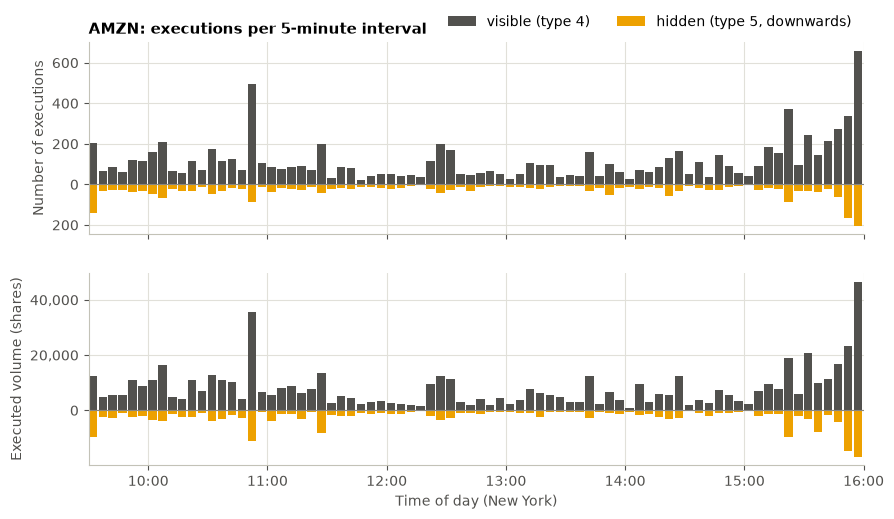

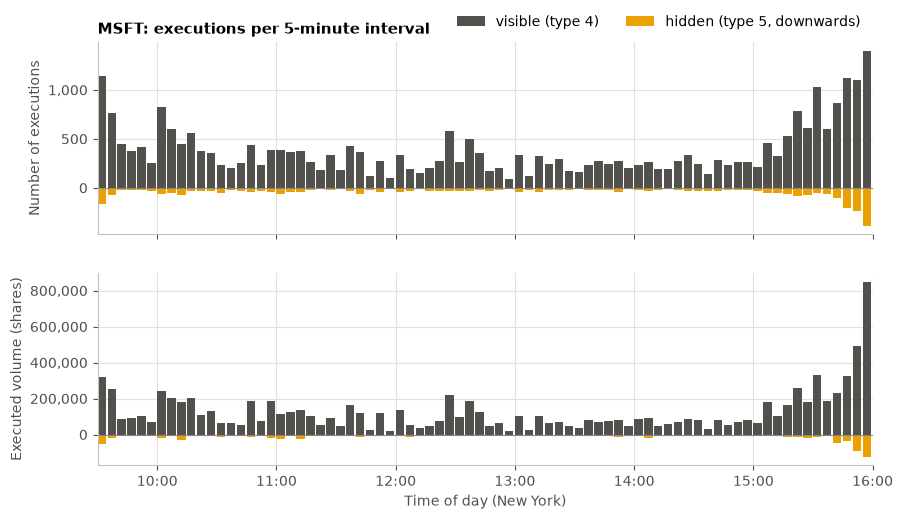

In [21]:
def executions_by_interval(msg, freq="5min"):
    """Number of executions and executed volume in each time interval, split into visible and hidden."""
    executions = msg[msg["Type"].isin([4, 5])]
    kind = np.where(executions["Type"] == 4, "visible", "hidden")
    out = executions.groupby([pd.Grouper(freq=freq), kind])["Size"].agg(["count", "sum"]).unstack().fillna(0)
    out.columns = [("n_" if stat == "count" else "vol_") + k for stat, k in out.columns]
    for column in ("n_visible", "n_hidden", "vol_visible", "vol_hidden"):
        if column not in out:
            out[column] = 0.0
    return out


def visible_hidden_plot(msg, ticker, freq="5min"):
    """Plot the number of executions and the executed volume per interval; hidden executions point downwards."""
    data = executions_by_interval(msg, freq)
    x, width = hours(data.index), pd.Timedelta(freq) / pd.Timedelta(hours=1)

    fig, axs = plt.subplots(2, 1, sharex=True, figsize=(10, 5.5))
    for ax, prefix, ylabel in [(axs[0], "n_", "Number of executions"), (axs[1], "vol_", "Executed volume (shares)")]:
        ax.bar(x, data[prefix + "visible"], width=0.85 * width, align="edge", color=VISIBLE_COLOR, label="visible (type 4)")
        ax.bar(x, -data[prefix + "hidden"], width=0.85 * width, align="edge", color=HIDDEN_COLOR, label="hidden (type 5, downwards)")
        ax.axhline(0, color=MUTED, linewidth=0.8)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(v):,.0f}"))
        ax.set_ylabel(ylabel)
    axs[0].set_title(f"{ticker}: executions per {freq.replace('min', '-minute')} interval")
    axs[0].legend(ncol=2, loc="lower right", bbox_to_anchor=(1, 1))
    time_axis(axs[1])
    plt.show()
    return data


exec_5min = {ticker: visible_hidden_plot(msg_book[ticker], ticker) for ticker in STOCKS}

AMZN: hidden executions are 24.4% of the executed volume over the whole day; 2.6% of them trade at a price that is not a whole number of cents
MSFT: hidden executions are 8.7% of the executed volume over the whole day; 48.8% of them trade at a price that is not a whole number of cents


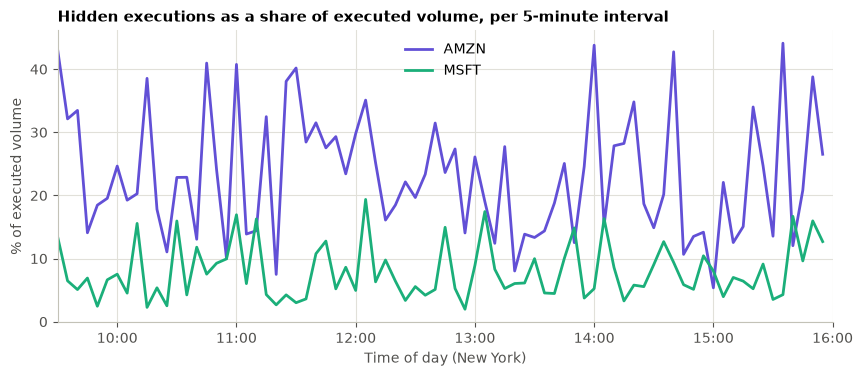

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for ticker in STOCKS:
    data = exec_5min[ticker]
    hidden_share = 100 * data["vol_hidden"] / (data["vol_hidden"] + data["vol_visible"])
    ax.plot(hours(data.index), hidden_share, color=TICKER_COLORS[ticker], label=ticker)
    total = 100 * data["vol_hidden"].sum() / (data["vol_hidden"].sum() + data["vol_visible"].sum())
    hidden = msg_book[ticker][msg_book[ticker]["Type"] == 5]
    print(f"{ticker}: hidden executions are {total:.1f}% of the executed volume over the whole day; "
          f"{100 * (hidden['Price'] % TICK != 0).mean():.1f}% of them trade at a price that is not a whole number of cents")
ax.set_title("Hidden executions as a share of executed volume, per 5-minute interval")
ax.set_ylabel("% of executed volume")
ax.legend()
time_axis(ax)
plt.show()

On NASDAQ the tick size is one cent, so every *displayed* order sits on a price like $30.13 or $30.14. 
Nothing visible can be quoted at $30.135. In LOBSTER units (price × 10,000) a whole number of cents is a multiple of 100: $30.13 is 301300, $30.14 is 301400. 

hidden["Price"] % TICK != 0 asks whether the price of each hidden execution is not a multiple of 100, so 301350 (= $30.135) counts, 301300 does not.

Why does this happen at all? Hidden orders are exempt from the one-cent grid of the sub-penny rule (lecture notes §2.3.1): the rule restricts quoting, not execution. The common case is a hidden mid-point order: when the spread is one tick, the mid-price is half a cent ($30.135 between a $30.13 bid and a $30.14 ask), and a hidden order pegged to the mid-point trades exactly there. For the trader it is the only way to trade inside a locked one-tick spread, half a tick better than the quote on each side.

That’s why the numbers are so different: 49% of MSFT’s hidden executions are off the cent grid, because its spread is one tick almost all day and the mid-point is the natural hidden price; only 3% for AMZN, whose spread is 13 ticks wide, so hidden orders there are placed at ordinary cent prices somewhere inside the spread. 

In [18]:
# the most common hidden execution prices for MSFT:
(msg_book["MSFT"].loc[msg_book["MSFT"]["Type"] == 5, "Price"] / PRICE_SCALE).value_counts().head()

Price
30.115    106
30.110    106
30.135     89
30.145     88
30.105     88
Name: count, dtype: int64

> **Question 1.8.** In which of the two stocks is hidden liquidity used more? Why? (Lecture notes §2.2.2 and Question 2.20.)

**Answer.** Hidden executions are 24% of the executed volume for AMZN against 9% for MSFT. This is what §2.5 leads us to expect: traders make heavy use of hidden orders in small-tick stocks and little use of them in large-tick stocks (see also Figure 3.4).

- In a **small-tick** stock, price priority is cheap: anyone can step ahead of a displayed order by improving its price by one economically negligible tick. Displaying a large order gives the rest of the market a free option (§2.2.2), so traders hide.
- In a **large-tick** stock the spread is locked at one tick and the queues are long. A hidden order has lower priority than every visible order at the same price, so at the best quote it would wait behind the whole visible queue. Hiding is costly and rarely worthwhile (this is the answer to Question 2.20).
- Look at *where* MSFT's hidden orders trade: about half of its hidden executions are at prices that are not a whole number of cents, such as \$30.135, the mid-price when the spread is one tick. A hidden mid-point order is the only way to trade *inside* a one-tick spread. For AMZN this happens for only 3% of the hidden executions.

---
# Part 2 — The order book file

## 2.1 What is in it?

The order book file has **one row per row of the message file**: the state of the book right *after* the corresponding event. With $N$ levels it has $4N$ columns, ordered as

`Ask Price 1, Ask Size 1, Bid Price 1, Bid Size 1, Ask Price 2, Ask Size 2, Bid Price 2, Bid Size 2, …`

Level 1 is the best quote on each side; prices are again in dollars × 10,000. A level with no orders is filled with the price `9999999999` on the ask side (`-9999999999` on the bid side) and size 0.

`load_orderbook` reads the file, keeps the rows that survived the 09:30–16:00 filter of the message file (this is what `row_index` is for), and returns a dictionary of four aligned tables: ask prices, ask sizes, bid prices and bid sizes. Prices are kept in LOBSTER units; we divide by 10,000 only when we need dollars.

In [19]:
BOOK_TABLES = ["Ask Price", "Ask Size", "Bid Price", "Bid Size"]


def load_orderbook(ticker, msg, date=None, levels=None, chunk_rows=500_000):
    """Load a LOBSTER orderbook file aligned with `msg`. Returns a dict of four DataFrames (one column per level)."""
    files = lobster_files(ticker, date, levels)
    n_levels = files["levels"]
    names = [f"{table} {level}" for level in range(1, n_levels + 1) for table in BOOK_TABLES]
    dtypes = {name: ("int64" if "Price" in name else "int32") for name in names}     # compact types

    # These files are big (up to 2.4 million rows x 40 columns). To keep the memory use low we read them in
    # chunks of rows and split each chunk into the four tables straight away: the columns of a table are
    # every 4th column of the file, starting at column 0, 1, 2 or 3.
    pieces = {table: [] for table in BOOK_TABLES}
    for chunk in pd.read_csv(files["orderbook"], header=None, names=names, dtype=dtypes, chunksize=chunk_rows):
        for i, table in enumerate(BOOK_TABLES):
            pieces[table].append(chunk.iloc[:, i::4].copy())
    book = {table: pd.concat(pieces.pop(table)) for table in BOOK_TABLES}

    # keep exactly the rows kept in the message file, and give them the same time index
    n_rows = len(book["Ask Price"])
    assert n_rows > msg["row_index"].max(), "message and orderbook files do not have the same number of rows"
    for table in BOOK_TABLES:
        if n_rows != len(msg):
            book[table] = book[table].iloc[msg["row_index"].to_numpy()]
        book[table].index = msg.index
    return book


OB = {ticker: load_orderbook(ticker, msg_book[ticker]) for ticker in STOCKS}

OB
├── "AMZN"
│   ├── "Ask Price"  → DataFrame, 269,748 rows × 10 columns: Ask Price 1 … Ask Price 10
│   ├── "Ask Size"   → DataFrame, 269,748 rows × 10 columns: Ask Size 1 … Ask Size 10
│   ├── "Bid Price"  → DataFrame, 269,748 rows × 10 columns: Bid Price 1 … Bid Price 10
│   └── "Bid Size"   → DataFrame, 269,748 rows × 10 columns: Bid Size 1 … Bid Size 10
└── "MSFT"
    ├── "Ask Price"  → 668,765 rows × 10
    ├── "Ask Size"
    ├── "Bid Price"
    └── "Bid Size"

The output is a dictionary of tables. Each row is the book after one event, so every table must have exactly as many rows as the message table. Let us check.

In [20]:
def data_checker(book, msg, ticker=""):
    for table, values in book.items():
        assert values.shape[0] == msg.shape[0], f"{ticker} {table}: {values.shape[0]} rows, expected {msg.shape[0]}"
        print(f"ok!  {ticker:5s} {table:10s} {values.shape}")


for ticker in STOCKS:
    data_checker(OB[ticker], msg_book[ticker], ticker)

ok!  AMZN  Ask Price  (269748, 10)
ok!  AMZN  Ask Size   (269748, 10)
ok!  AMZN  Bid Price  (269748, 10)
ok!  AMZN  Bid Size   (269748, 10)
ok!  MSFT  Ask Price  (668765, 10)
ok!  MSFT  Ask Size   (668765, 10)
ok!  MSFT  Bid Price  (668765, 10)
ok!  MSFT  Bid Size   (668765, 10)


In [21]:
# So the raw 40 column orderbook file (Ask Price 1, Ask Size 1, Bid Price 1, Bid Size 1, Ask Price 2, …) has simply been cut into four 10 column tables: 

OB["AMZN"]["Ask Price"]                 # all ask prices, all events
OB["AMZN"]["Ask Price"]["Ask Price 1"]  # the best ask through the day (a Series)
OB["AMZN"]["Bid Size"].iloc[1000]       # the ten bid volumes right after event number 1000
OB["AMZN"]["Bid Size"].loc["2012-06-21 11:00"]  # same, for the events in that minute

,Bid Size 1,Bid Size 2,Bid Size 3,Bid Size 4,Bid Size 5,Bid Size 6,Bid Size 7,Bid Size 8,Bid Size 9,Bid Size 10
DateTime,,,,,,,,,,
2012-06-21 11:00:00.133492026,100,300,20,20,26,126,400,201,200,214
2012-06-21 11:00:00.560059285,100,300,20,20,26,126,400,201,100,200
2012-06-21 11:00:00.565628076,100,300,20,20,26,126,400,201,200,200
2012-06-21 11:00:00.679919711,100,300,20,20,26,126,400,201,200,200
2012-06-21 11:00:00.680113853,100,300,20,20,26,126,400,201,200,200
...,...,...,...,...,...,...,...,...,...,...
2012-06-21 11:00:58.458086853,144,18,99,300,100,114,100,300,200,200
2012-06-21 11:00:59.269221949,144,18,99,300,100,114,100,300,200,200
2012-06-21 11:00:59.269226192,144,18,99,300,100,114,100,300,200,200


> **Question 2.1.** Look at the structure of the data: what do the rows and the columns of each table represent?

In [23]:
OB["AMZN"]["Bid Price"].head()

,Bid Price 1,Bid Price 2,Bid Price 3,Bid Price 4,Bid Price 5,Bid Price 6,Bid Price 7,Bid Price 8,Bid Price 9,Bid Price 10
DateTime,,,,,,,,,,
2012-06-21 09:30:00.017459617,2231800,2230700,2230400,2230000,2226200,2213000,2204000,2202500,2202000,2189700
2012-06-21 09:30:00.189607670,2238100,2231800,2230700,2230400,2230000,2226200,2213000,2204000,2202500,2202000
2012-06-21 09:30:00.189607670,2238100,2231800,2230700,2230400,2230000,2226200,2213000,2204000,2202500,2202000
2012-06-21 09:30:00.189607670,2238100,2237500,2231800,2230700,2230400,2230000,2226200,2213000,2204000,2202500
2012-06-21 09:30:00.189607670,2238100,2237500,2231800,2230700,2230400,2230000,2226200,2213000,2204000,2202500


## 2.2 Best quotes, spread, mid-price and gaps

From the first two levels we can compute, for every event, the quantities defined in the lecture notes (Definition 2.5 and §2.5):

- best bid $b(t)$ and best ask $a(t)$, and the volumes available there (the **depth at the best**);
- the **bid–ask spread** $s(t) = a(t) - b(t)$;
- the **mid-price** $x(t) = \tfrac12 [a(t) + b(t)]$;
- the **first gap** $d_1$ on each side: the distance between the best and the second-best price.

> **Question 2.2.** Compute the bid, ask, mid-price, spread and first gaps associated with each event.

In [26]:
def top_of_book(book):
    """Best quotes and the quantities derived from them, one row per event (prices in LOBSTER units)."""
    ask, bid = book["Ask Price"], book["Bid Price"]
    top = pd.DataFrame({
        "bid": bid["Bid Price 1"], "ask": ask["Ask Price 1"],
        "bid_size": book["Bid Size"]["Bid Size 1"], "ask_size": book["Ask Size"]["Ask Size 1"],
    })
    top["mid"] = (top["ask"] + top["bid"]) / 2
    top["spread"] = top["ask"] - top["bid"]
    # first gaps; a missing second level (LOBSTER's filler price) gives NaN rather than a huge number
    top["gap_ask"] = (ask["Ask Price 2"] - ask["Ask Price 1"]).where(ask["Ask Price 2"].abs() < EMPTY_LEVEL)
    top["gap_bid"] = (bid["Bid Price 1"] - bid["Bid Price 2"]).where(bid["Bid Price 2"].abs() < EMPTY_LEVEL)
    return top


top = {ticker: top_of_book(OB[ticker]) for ticker in STOCKS}
top["AMZN"].head()

,bid,ask,bid_size,ask_size,mid,spread,gap_ask,gap_bid
DateTime,,,,,,,,
2012-06-21 09:30:00.017459617,2231800,2239500,100,100,2235650.0,7700,400,1100
2012-06-21 09:30:00.189607670,2238100,2239500,21,100,2238800.0,1400,400,6300
2012-06-21 09:30:00.189607670,2238100,2239500,21,100,2238800.0,1400,100,6300
2012-06-21 09:30:00.189607670,2238100,2239500,21,100,2238800.0,1400,100,600
2012-06-21 09:30:00.189607670,2238100,2239500,21,100,2238800.0,1400,100,600


In [20]:
for ticker in STOCKS:
    t = top[ticker]
    print(f"{ticker}: mid-price from ${t['mid'].min() / PRICE_SCALE:,.2f} to ${t['mid'].max() / PRICE_SCALE:,.2f} | "
          f"spread from {t['spread'].min() / TICK:.0f} to {t['spread'].max() / TICK:.0f} ticks "
          f"(mean {t['spread'].mean() / TICK:.2f}) | "
          f"mean first gap: ask {t['gap_ask'].mean() / TICK:.2f}, bid {t['gap_bid'].mean() / TICK:.2f} ticks")

AMZN: mid-price from $220.52 to $226.03 | spread from 1 to 77 ticks (mean 13.09) | mean first gap: ask 2.19, bid 2.79 ticks
MSFT: mid-price from $30.07 to $31.14 | spread from 1 to 5 ticks (mean 1.23) | mean first gap: ask 1.00, bid 1.00 ticks


**A sanity check worth remembering.** If the two files are correctly aligned and we read `TradeDirection` correctly, every visible execution must take place at the best quote that was in force *just before* it, i.e. on the previous row: at the best **ask** when a sell limit order is executed (`TradeDirection = -1`, a buyer-initiated trade) and at the best **bid** when a buy limit order is executed (`TradeDirection = +1`, a seller-initiated trade).

In [28]:
for ticker in STOCKS:
    m, t = msg_book[ticker], top[ticker]
    is_execution = (m["Type"] == 4).to_numpy().copy()
    is_execution[0] = False                                        # the first row has no "book before"
    direction, price = m["TradeDirection"].to_numpy()[is_execution], m["Price"].to_numpy()[is_execution]
    ask_before = t["ask"].shift(1).to_numpy()[is_execution]        # shift(1): the book on the previous row
    bid_before = t["bid"].shift(1).to_numpy()[is_execution]
    print(f"{ticker}: executions of sell limit orders at the previous best ask: "
          f"{100 * np.mean(price[direction == -1] == ask_before[direction == -1]):.1f}% | "
          f"executions of buy limit orders at the previous best bid: "
          f"{100 * np.mean(price[direction == 1] == bid_before[direction == 1]):.1f}%")

AMZN: executions of sell limit orders at the previous best ask: 100.0% | executions of buy limit orders at the previous best bid: 100.0%
MSFT: executions of sell limit orders at the previous best ask: 100.0% | executions of buy limit orders at the previous best bid: 100.0%


Both are 100%: the files are aligned, the book *before* an event is on the previous row, and `TradeDirection` is indeed the side of the limit order that was executed.

**Remark (one flat table).** Because the two files are aligned row by row, they can also be glued side by side into a single table: the event, followed by the state of the book it produced. 

In [30]:
def merge_message_orderbook(msg, book):
    """Message file and order book file side by side: one row per event, followed by the resulting book."""
    n_levels = book["Bid Price"].shape[1]
    columns = [book[f"{side} {what}"][f"{side} {what} {level}"].rename(f"{side} {'Price' if what == 'Price' else 'Volume'} {level}")
               for level in range(1, n_levels + 1) for side in ("Bid", "Ask") for what in ("Price", "Size")]
    flat = pd.concat([msg.reset_index()] + [c.reset_index(drop=True) for c in columns], axis=1)
    return flat.set_index("DateTime")


merged_amzn = merge_message_orderbook(msg_book["AMZN"], OB["AMZN"])
print(merged_amzn.shape)
display(merged_amzn.iloc[:5, :15])
del merged_amzn                                        # we will not need it again in this lab

(269748, 47)


,Time,Type,OrderID,Size,Price,TradeDirection,row_index,Bid Price 1,Bid Volume 1,Ask Price 1,Ask Volume 1,Bid Price 2,Bid Volume 2,Ask Price 2,Ask Volume 2
DateTime,,,,,,,,,,,,,,,
2012-06-21 09:30:00.017459617,34200.017460,5,0,1,2238200,-1,0,2231800,100,2239500,100,2230700,200,2239900,100
2012-06-21 09:30:00.189607670,34200.189608,1,11885113,21,2238100,1,1,2238100,21,2239500,100,2231800,100,2239900,100
2012-06-21 09:30:00.189607670,34200.189608,1,3911376,20,2239600,-1,2,2238100,21,2239500,100,2231800,100,2239600,20
2012-06-21 09:30:00.189607670,34200.189608,1,11534792,100,2237500,1,3,2238100,21,2239500,100,2237500,100,2239600,20
2012-06-21 09:30:00.189607670,34200.189608,1,1365373,13,2240000,-1,4,2238100,21,2239500,100,2237500,100,2239600,20


## 2.3 A snapshot of the book

`order_book_look` draws the book in force at a given time of day (a random event if no time is given): the volume resting at each price level, and below it the **relative depth profile** — the cumulative share of the displayed volume as we move away from the best quotes.

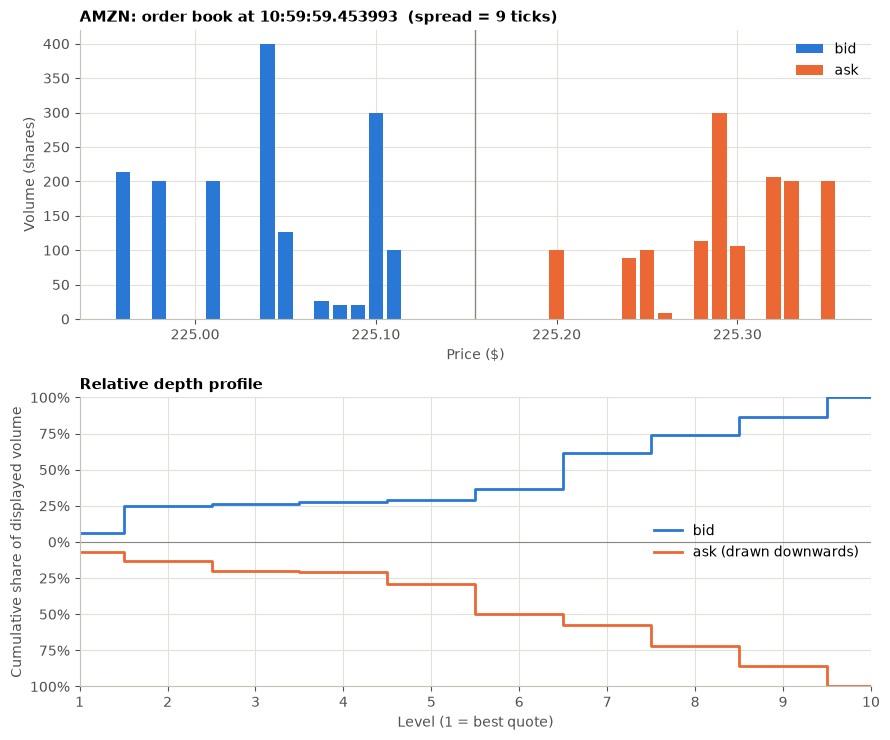

In [24]:
def book_position(book, when):
    """Row number of the last event at or before the time of day `when` (e.g. '11:00:00')."""
    index = book["Bid Price"].index
    stamp = pd.Timestamp.combine(index[0].date(), pd.Timestamp(when).time())
    return max(index.searchsorted(stamp, side="right") - 1, 0)


def plot_book(ax, bid_prices, bid_sizes, ask_prices, ask_sizes, title="", max_levels=None):
    """Bar chart of the volume available at each price level (prices in LOBSTER units)."""
    # Converts prices to dollars (÷ 10,000), drops empty levels (size 0), and draws one bar per level: bids in blue, asks in orange, height = shares available at that price. 
    # A grey vertical line marks the mid price.
    # The title shows the spread in ticks, computed as (lowest ask − highest bid) / 0.01.
    bid_p, ask_p = np.asarray(bid_prices)[:max_levels] / PRICE_SCALE, np.asarray(ask_prices)[:max_levels] / PRICE_SCALE
    bid_s, ask_s = np.asarray(bid_sizes)[:max_levels], np.asarray(ask_sizes)[:max_levels]
    keep_bid, keep_ask = bid_s > 0, ask_s > 0                               # drop unoccupied levels
    bid_p, bid_s, ask_p, ask_s = bid_p[keep_bid], bid_s[keep_bid], ask_p[keep_ask], ask_s[keep_ask]

    price_range = ask_p.max() - bid_p.min()
    width = max(0.8 * TICK / PRICE_SCALE, price_range / 120)                # at least visible, at most one tick wide
    ax.bar(bid_p, bid_s, width=width, color=BID_COLOR, label="bid")
    ax.bar(ask_p, ask_s, width=width, color=ASK_COLOR, label="ask")
    ax.axvline((bid_p.max() + ask_p.min()) / 2, color=MUTED, linewidth=1)   # mid-price
    ax.xaxis.set_major_locator(MaxNLocator(nbins=7, steps=[1, 2, 5, 10]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda p, _: f"{p:,.2f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Price ($)")
    ax.set_ylabel("Volume (shares)")
    spread_ticks = int(round((ask_p.min() - bid_p.max()) * PRICE_SCALE / TICK))
    ax.set_title(f"{title}  (spread = {spread_ticks:,} tick{'s' if spread_ticks != 1 else ''})")
    ax.legend()


def order_book_look(book, ticker, when=None, seed=None):
    """Snapshot of the book at time of day `when` (random event if None) and its relative depth profile."""
    # If you give a time (when="11:00:00"), it uses book_position; if you don’t, it picks a random event. 
    # Then it takes that single row from each of the four tables: ten bid prices, ten bid sizes, ten ask prices, ten ask sizes. Each is now a list of ten numbers.
    if when is None:
        position = int(np.random.default_rng(seed).integers(len(book["Bid Price"])))
    else:
        position = book_position(book, when)
    stamp = book["Bid Price"].index[position]
    bid_p, bid_s = book["Bid Price"].iloc[position].to_numpy(), book["Bid Size"].iloc[position].to_numpy()
    ask_p, ask_s = book["Ask Price"].iloc[position].to_numpy(), book["Ask Size"].iloc[position].to_numpy()

    fig, axs = plt.subplots(2, 1, figsize=(9, 7.5))
    plot_book(axs[0], bid_p, bid_s, ask_p, ask_s, title=f"{ticker}: order book at {stamp.strftime('%H:%M:%S.%f')}")

    levels = np.arange(1, len(bid_s) + 1)
    axs[1].step(levels, bid_s.cumsum() / bid_s.sum(), where="mid", color=BID_COLOR, label="bid")
    axs[1].step(levels, -ask_s.cumsum() / ask_s.sum(), where="mid", color=ASK_COLOR, label="ask (drawn downwards)")
    axs[1].axhline(0, color=MUTED, linewidth=0.8)
    axs[1].set_xlim(1, len(levels)); axs[1].set_ylim(-1, 1); axs[1].set_xticks(levels)
    axs[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(v):.0%}"))
    axs[1].set_xlabel("Level (1 = best quote)")
    axs[1].set_ylabel("Cumulative share of displayed volume")
    axs[1].set_title("Relative depth profile")
    axs[1].legend(loc="center right")
    fig.tight_layout()
    plt.show()
    return stamp


snapshot_time = order_book_look(OB["AMZN"], "AMZN", when="11:00:00")

Take the ten bid sizes of the snapshot and add them up as you go deeper into the book. The plot shows that running total as a percentage of the ten level total:

x-axis: the level, 1 = best quote, 10 = tenth-best price;
y-axis: “of all the volume displayed on this side, what share sits at level k or better”.

How to read the shape:

- A straight diagonal (roughly 10% per level) means the volume is spread evenly over the ten prices. That’s MSFT: no level matters much more than the others, there’s a lot everywhere.
- A big jump means that one level holds a large chunk of the volume. In the AMZN snapshot the bid curve jumps from about 7% to 25% at level 2 and from about 37% to 62% at level 6: those are the two bars of 400 and 300 shares in the top panel. A long flat stretch means several levels with almost nothing.
- The height at level 1 answers “how much of what I can see is right at the best price?”

In [25]:
pos = book_position(OB["AMZN"], "11:00:00")
pd.DataFrame({"bid price": OB["AMZN"]["Bid Price"].iloc[pos].to_numpy() / PRICE_SCALE,
              "bid size":  OB["AMZN"]["Bid Size"].iloc[pos].to_numpy(),
              "ask price": OB["AMZN"]["Ask Price"].iloc[pos].to_numpy() / PRICE_SCALE,
              "ask size":  OB["AMZN"]["Ask Size"].iloc[pos].to_numpy()}, index=range(1, 11))

,bid price,bid size,ask price,ask size
1,225.11,100,225.20,100
2,225.10,300,225.24,88
3,225.09,20,225.25,100
4,225.08,20,225.26,8
5,225.07,26,225.28,113
6,225.05,126,225.29,300
7,225.04,400,225.30,106
8,225.01,201,225.32,206
9,224.98,200,225.33,200
10,224.96,214,225.35,200


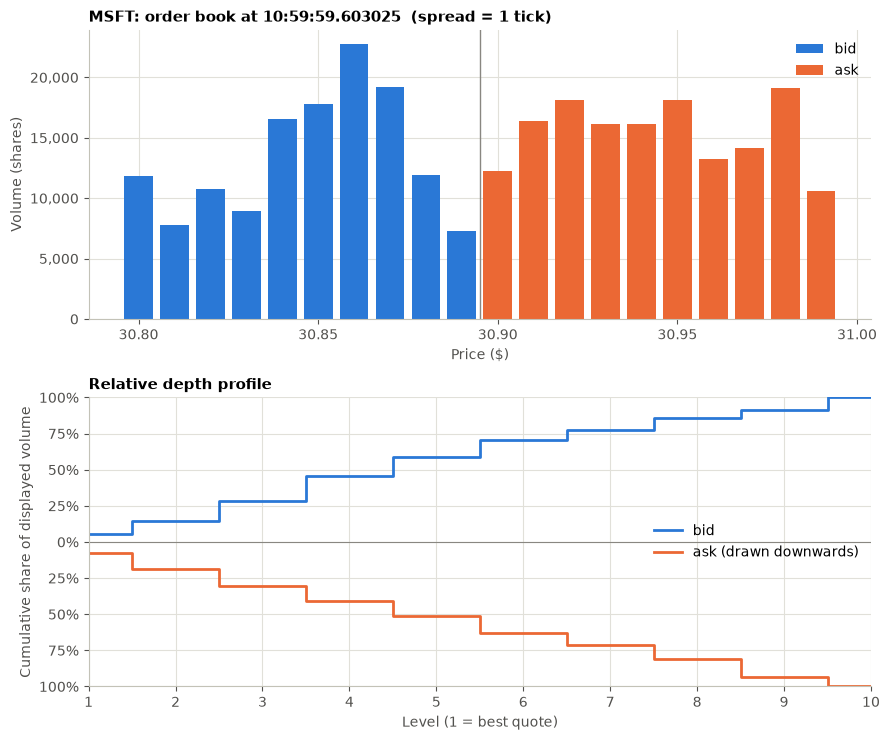

In [32]:
_ = order_book_look(OB["MSFT"], "MSFT", when="11:00:00")

> **Question 2.3.** Compare the two snapshots. What differs in (i) the spread, (ii) the spacing of the occupied price levels, and (iii) the volume available at each level? Re-run the function with other times of day, or with `when=None` for a random event.

**Answer.**

1. **Spread.** 9 ticks (\$0.09) for AMZN; 1 tick, the minimum possible, for MSFT.
2. **Occupied price levels.** The AMZN book is *sparse*: the ten best bids are spread over 15 cents and so are the ten best asks, with empty prices in between. The MSFT book is *dense*: every single cent is occupied, so ten levels cover exactly 9 ticks on each side.
3. **Volume.** No more than 400 shares at any AMZN level (about \$90 thousand) against 7,000 to 23,000 shares at each MSFT level (\$0.2–0.7 million). The depth profile of MSFT is almost a straight line (similar volume at every level); that of AMZN is irregular.

These are the typical snapshots of a small-tick and of a large-tick stock (compare with Figure 3.5 of the lecture notes).

---
# Part 3 — Event time vs clock time

LOBSTER writes a row only when something changes in the book, so the rows are **not** evenly spaced in time: events bunch together when the market is busy. *Event time* simply counts events (1, 2, 3, …) instead of seconds, and it is often the more natural clock for a limit order book (lecture notes §8.1.2).

Here is how fast the event clock runs through the day: the number of events per second, averaged over the previous five minutes.

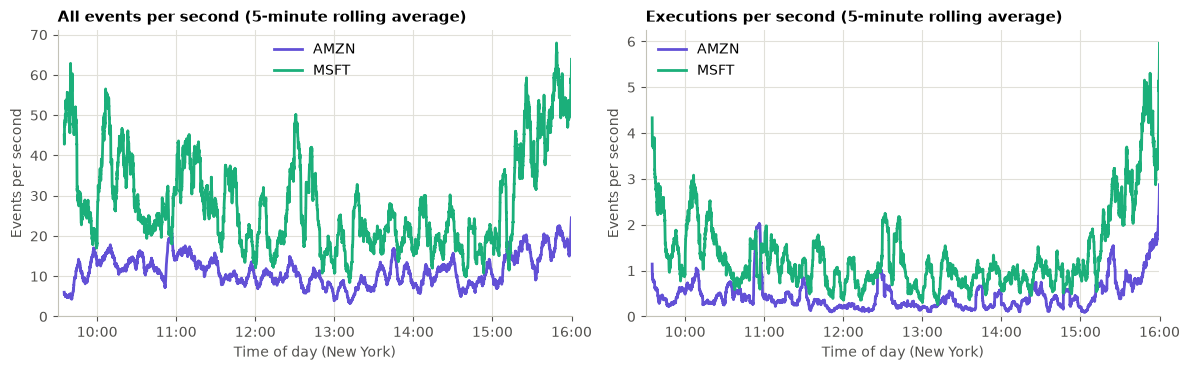

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ticker in STOCKS:
    m = msg_book[ticker]
    all_events = m.resample("1s").size().rolling(300).mean()
    executions = m[m["Type"].isin([4, 5])].resample("1s").size().rolling(300).mean()
    axs[0].plot(hours(all_events.index), all_events, color=TICKER_COLORS[ticker], label=ticker)
    axs[1].plot(hours(executions.index), executions, color=TICKER_COLORS[ticker], label=ticker)
axs[0].set_title("All events per second (5-minute rolling average)")
axs[1].set_title("Executions per second (5-minute rolling average)")
for ax in axs:
    ax.set_ylabel("Events per second")
    ax.set_ylim(bottom=0)
    ax.legend()
    time_axis(ax)
fig.tight_layout()
plt.show()

> **Question 3.1.** When is the market most active? Is the pattern the same for all events and for executions only?

**Answer.** Activity is highest just after the open and, above all, before the close, and lowest around lunchtime: the familiar U-shape (closer to a J on this day). MSFT goes from 50–60 events per second in the first minutes to about 20 around 13:00 and back above 50 before 16:00. Executions follow the same pattern even more sharply (about one per second at midday against four to five near the close), and they are about twenty times rarer than events in general.

A fixed number of events therefore covers very different amounts of clock time during the day. Keep this in mind whenever you average "over the last $N$ events".

---
# Part 4 — Liquidity and risk indicators: a small-tick and a large-tick stock